In [1]:
import re
from pathlib import Path
import gc, shutil
import pandas as pd
import requests
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "scripts" else Path.cwd()
DATA = ROOT/"data"
MODES = ["subway", "bus", "streetcar"]

In [2]:
CKAN = "https://ckan0.cf.opendata.inter.prod-toronto.ca/api/3/action/package_show"
DATASETS = {
    "subway": "ttc-subway-delay-data",
    "bus": "ttc-bus-delay-data",
    "streetcar": "ttc-streetcar-delay-data",
}


def get_resources(slug):
    r = requests.get(CKAN, params={"id": slug}, timeout=60)
    r.raise_for_status()
    return r.json()["result"]["resources"]


def is_unique(res):
    """Keep delay data files only (skip readme, code lists, duplicate formats)."""
    name = res["name"].lower()
    fmt = (res.get("format") or "").lower()
    if "readme" in name or "code" in name:
        return False
    # Live "since 2025" tables are published in 4 formats; keep only the CSV copy.
    return not (res.get("datastore_active") or fmt in ("xml", "json"))


def download(url, dest):
    if dest.exists() and dest.stat().st_size > 0:
        return dest
    dest.parent.mkdir(parents=True, exist_ok=True)
    with requests.get(url, stream=True, timeout=300) as r:
        r.raise_for_status()
        tmp = dest.with_suffix(dest.suffix + ".part")
        with open(tmp, "wb") as f:
            for chunk in r.iter_content(1 << 20):
                f.write(chunk)
        tmp.rename(dest)
    return dest

for mode in MODES:
    resources = get_resources(DATASETS[mode])
    print(f"\n== {mode}: {len(resources)} resources")
    for res in resources:
        keep = is_unique(res)
        print(f"  [{'get' if keep else 'skip':4}] {res['format']:4} {res['name'].strip()}")
        if keep:
            fname = res["url"].rsplit("/", 1)[-1]
            download(res["url"], DATA / "raw" / mode / fname)


== subway: 19 resources
  [skip] XLSX ttc-subway-delay-codes
  [skip] XLSX ttc-subway-delay-data-readme
  [get ] XLSX ttc-subway-delay-jan-2014-april-2017
  [get ] XLSX ttc-subway-delay-may-december-2017
  [get ] XLSX ttc-subway-delay-data-2018
  [get ] XLSX ttc-subway-delay-data-2019
  [get ] XLSX ttc-subway-delay-data-2020
  [get ] XLSX ttc-subway-delay-data-2021
  [get ] XLSX ttc-subway-delay-data-2022
  [get ] XLSX ttc-subway-delay-data-2023
  [get ] XLSX ttc-subway-delay-data-2024
  [skip] XLSX TTC Subway Delay Data since 2025
  [get ] CSV  TTC Subway Delay Data since 2025.csv
  [skip] XML  TTC Subway Delay Data since 2025.xml
  [skip] JSON TTC Subway Delay Data since 2025.json
  [skip] XLSX Code Descriptions
  [skip] CSV  Code Descriptions.csv
  [skip] XML  Code Descriptions.xml
  [skip] JSON Code Descriptions.json

== bus: 20 resources
  [skip] XLSX ttc-bus-delay-data-readme
  [get ] XLSX ttc-bus-delay-data-2014
  [get ] XLSX ttc-bus-delay-data-2015
  [get ] XLSX ttc-bus-delay-

In [3]:
subway_2025 = pd.read_csv(DATA/"raw"/"subway"/"ttc-subway-delay-data-since-2025.csv")
bus_2025 = pd.read_csv(DATA/"raw"/"bus"/"ttc-bus-delay-data-since-2025.csv")
streetcar_2025 = pd.read_csv(DATA/"raw"/"streetcar"/"ttc-streetcar-delay-data-since-2025.csv")

display(subway_2025)
display(bus_2025)
display(streetcar_2025)

,_id,Date,Time,Day,Station,Code,Min Delay,Min Gap,Bound,Line,Vehicle
0,1,2025-01-01,02:10,Wednesday,BATHURST STATION,MUSAN,5,9,E,BD,5227
1,2,2025-01-01,02:30,Wednesday,DUNDAS STATION,MUIRS,0,0,NaN,YU,0
2,3,2025-01-01,02:32,Wednesday,BROADVIEW STATION,PUMST,0,0,E,BD,0
3,4,2025-01-01,02:58,Wednesday,KEELE STATION,EUSC,0,0,W,BD,5293
4,5,2025-01-01,02:58,Wednesday,COXWELL STATION,SUAE,0,0,NaN,BD,0
...,...,...,...,...,...,...,...,...,...,...,...
47910,47911,2026-09-30,15:16,Wednesday,BAYVIEW STATION,PUSTS,0,0,W,SHP,6141
47911,47912,2026-09-30,15:33,Wednesday,DON MILLS STATION,MUO,0,0,W,SHP,6146
47912,47913,2026-09-30,15:49,Wednesday,SHEPPARD-YONGE STATION,MUO,0,0,E,SHP,6146
47913,47914,2026-09-30,19:04,Wednesday,LESLIE STATION,TUMVS,5,10,E,SHP,6191


,_id,Date,Line,Time,Day,Station,Code,Min Delay,Min Gap,Bound,Vehicle
0,1,2025-01-01T00:00:00,102 MARKHAM ROAD,02:15,Wednesday,WARDEN STATION,MFESA,20,40,N,3442
1,2,2025-01-01T00:00:00,65 PARLIAMENT,02:15,Wednesday,KIPLING STATION,MFUS,0,0,NaN,0
2,3,2025-01-01T00:00:00,64 MAIN,02:40,Wednesday,BROADVIEW STATION,MFUI,0,0,NaN,8546
3,4,2025-01-01T00:00:00,100 FLEMINGDON PARK,02:43,Wednesday,OVERLEA AND THORNCLIFF,MFSAN,17,32,N,8693
4,5,2025-01-01T00:00:00,34 EGLINTON EAST,03:05,Wednesday,EGLINTON AND DON MILLS,MFUI,20,40,W,8801
...,...,...,...,...,...,...,...,...,...,...,...
107344,107345,2026-09-30T00:00:00,21 BRIMLEY,00:07,Wednesday,BRIMLEY AND STEELES,MFDV,37,57,N,8599
107345,107346,2026-09-30T00:00:00,149 ETOBICOKE-BLOOR,00:33,Wednesday,BLOOR AND OLD MILL TRA,EFO,20,40,E,3361
107346,107347,2026-09-30T00:00:00,94 WELLESLEY,00:44,Wednesday,WELLESLEY STATION,SFDP,11,22,NaN,8469
107347,107348,2026-09-30T00:00:00,65 PARLIAMENT,01:31,Wednesday,QUEENS QUAY AND SHERBO,MFBIO,13,26,N,8513


,_id,Date,Line,Time,Day,Station,Code,Min Delay,Min Gap,Bound,Vehicle
0,1,2025-01-01,504 KING,02:10,Wednesday,KING AND PARLIAMENT,MTSAN,10,20,W,4569
1,2,2025-01-01,506 CARLTON,02:50,Wednesday,COLLEGE AND HURON,MTAFR,34,49,E,4480
2,3,2025-01-01,504 KING,03:11,Wednesday,KING AND QUEEN EAST,MTIE,15,30,E,4629
3,4,2025-01-01,501 QUEEN,05:14,Wednesday,QUEEN AND DUFFERIN,MTAFR,36,55,E,4455
4,5,2025-01-01,504 KING,06:14,Wednesday,LESLIE CARHOUSE,MTVIS,10,20,E,4483
...,...,...,...,...,...,...,...,...,...,...,...
24759,24760,2026-09-30,501 QUEEN,23:39,Wednesday,HUMBER LOOP,STL,10,20,NaN,4437
24760,24761,2026-09-30,511 BATHURST,00:39,Wednesday,BATHURST STATION,MTUI,31,41,NaN,4479
24761,24762,2026-09-30,512 ST. CLAIR,00:48,Wednesday,ST CLAIR AND OAKWOOD,MFUIR,0,0,N,8768
24762,24763,2026-09-30,506 CARLTON,01:15,Wednesday,DUNDAS AND JARVIS,STDP,0,0,W,4426


In [4]:
ALIASES = {
    "date": "date", 
    "report date": "date",
    "time": "time",
    "day": "day",
    "route": "route", 
    "line": "route",
    "location": "location", 
    "station": "location",
    "incident": "incident", 
    "code": "incident",
    "min delay": "delay", 
    "delay": "delay",
    "min gap": "gap", 
    "gap": "gap",
    "direction": "direction", 
    "bound": "direction",
    "vehicle": "vehicle",
}
COLUMNS = [
    "date", 
    "time", 
    "day", 
    "route", 
    "location", 
    "incident", 
    "delay", 
    "gap", 
    "direction", 
    "vehicle"
]


def read_raw(path): #A CSV, or every sheet of an XLSX (older years have one sheet per month)
    if path.suffix.lower() == ".csv":
        return [pd.read_csv(path, dtype=str)]
    return list(pd.read_excel(path, sheet_name=None, dtype=str).values())


def rename(df):
    df.columns = [ALIASES.get(re.sub(r"\s+", " ", str(c)).strip().lower(), c) for c in df.columns]
    return df.reindex(columns=COLUMNS) # Keep the standard columns


frames = []
for mode in MODES:
    for path in sorted((DATA / "raw" / mode).glob("*")):
        for df in read_raw(path):
            frames.append(rename(df).assign(mode=mode))
df = pd.concat(frames, ignore_index=True)

def rows(label):
    print(f"{label:<40} {len(df):>9,} rows")

In [5]:
display(df)

,date,time,day,route,location,incident,delay,gap,direction,vehicle,mode
0,2020-01-01 00:00:00,01:18,Wednesday,SRT,KENNEDY SRT STATION,SRDP,8,13,N,3025,subway
1,2020-01-01 00:00:00,01:27,Wednesday,YU,SHEPPARD WEST STATION,MUI,7,12,S,5591,subway
2,2020-01-01 00:00:00,02:22,Wednesday,BD,MAIN STREET STATION,EUNT,3,7,W,5371,subway
3,2020-01-01 00:00:00,03:54,Wednesday,BD,KIPLING STATION,MUIS,0,0,E,5243,subway
4,2020-01-01 00:00:00,08:07,Wednesday,BD,KEELE STATION,MUNOA,4,9,W,5011,subway
...,...,...,...,...,...,...,...,...,...,...,...
1264843,2026-09-30,23:39,Wednesday,501 QUEEN,HUMBER LOOP,STL,10,20,NaN,4437,streetcar
1264844,2026-09-30,00:39,Wednesday,511 BATHURST,BATHURST STATION,MTUI,31,41,NaN,4479,streetcar
1264845,2026-09-30,00:48,Wednesday,512 ST. CLAIR,ST CLAIR AND OAKWOOD,MFUIR,0,0,N,8768,streetcar
1264846,2026-09-30,01:15,Wednesday,506 CARLTON,DUNDAS AND JARVIS,STDP,0,0,W,4426,streetcar


In [6]:
# Trim whitespace
for c in COLUMNS:
    df[c] = df[c].str.strip().mask(lambda s: s == "")

# Dates and times
df["date"] = pd.to_datetime(df["date"], format="mixed", errors="coerce").dt.normalize()
t = df["time"].str.split(" ").str[-1]
t = t.where(t.str.count(":") != 1, t + ":00")
df["datetime"] = df["date"] + pd.to_timedelta(t, errors="coerce")
df["time"] = df["datetime"].dt.strftime("%H:%M")
df = df[df["date"].notna()]
print(f"Dropped rows with no date: {len(df):,} rows")

# Delay and gap minutes: numeric, negatives become missing
for c in ["delay", "gap"]:
    x = pd.to_numeric(df[c], errors="coerce")
    df[c] = x.mask(x < 0)
df = df[df["delay"].notna() | df["gap"].notna()]
print(f"Dropped rows with no delay and no gap: {len(df):,} rows")

# Duplicates because some years are published twice
df = df.drop_duplicates()
print(f"Dropped exact duplicates: {len(df):,} rows")

# Save
df = df[["mode", "datetime"] + COLUMNS].sort_values(["mode", "datetime"])
df.to_csv(DATA / "ttc_cleaned.csv", index=False)
print("Saved ttc_cleaned.csv")

# Delete raw files and free RAM
for p in sorted((DATA / "raw").rglob("*"), reverse=True):
    p.rmdir() if p.is_dir() else p.unlink()
(DATA / "raw").rmdir()
del frames
gc.collect()

Dropped rows with no date: 1,264,848 rows
Dropped rows with no delay and no gap: 1,264,404 rows
Dropped exact duplicates: 1,254,253 rows
Saved ttc_cleaned.csv


0

In [7]:
ttc_cleaned = pd.read_csv(DATA / "ttc_cleaned.csv")
display(ttc_cleaned)

/var/folders/dv/8f4r5dp50yv_lywv_s27_ncw0000gn/T/ipykernel_84388/1746225885.py:1: DtypeWarning: Columns (0: route) have mixed types. Specify dtype option on import or set low_memory=False.
  ttc_cleaned = pd.read_csv(DATA / "ttc_cleaned.csv")


,mode,datetime,date,time,day,route,location,incident,delay,gap,direction,vehicle
0,bus,2014-01-01 00:23:00,2014-01-01,00:23,Wednesday,95,York Mills station,Mechanical,10.0,20.0,E,1734.0
1,bus,2014-01-01 00:55:00,2014-01-01,00:55,Wednesday,102,Entire run for route,General Delay,33.0,66.0,b/w,8110.0
2,bus,2014-01-01 01:28:00,2014-01-01,01:28,Wednesday,54,lawrence and Warden,Mechanical,10.0,20.0,WB,7478.0
3,bus,2014-01-01 01:30:00,2014-01-01,01:30,Wednesday,112,Kipling Station,Emergency Services,18.0,36.0,N,8084.0
4,bus,2014-01-01 01:37:00,2014-01-01,01:37,Wednesday,24,VP and Ellesmere,Investigation,10.0,20.0,n,7843.0
...,...,...,...,...,...,...,...,...,...,...,...,...
1254248,subway,2026-09-30 22:45:00,2026-09-30,22:45,Wednesday,BD,COXWELL STATION,TUNIP,6.0,10.0,E,5158.0
1254249,subway,2026-09-30 23:00:00,2026-09-30,23:00,Wednesday,YU,YONGE UNIVERSITY SUBWA,MUCP,0.0,0.0,NaN,0.0
1254250,subway,2026-09-30 23:12:00,2026-09-30,23:12,Wednesday,BD,PAPE STATION,SUL,0.0,0.0,NaN,0.0
1254251,subway,2026-09-30 23:56:00,2026-09-30,23:56,Wednesday,BD,BLOOR DANFORTH SUBWAY,MUGD,0.0,0.0,NaN,0.0


In [8]:
# Prepare data
# Writes data/ttc_prepared.csv.
OUTLIER_MIN = 600 # Cut-off to treat odd delays

df = pd.read_csv(DATA / "ttc_cleaned.csv", parse_dates=["datetime", "date"], dtype={"route": str, "vehicle": str})

# Remove decimal Excel added to some route and vehicle numbers
def drop_float_suffix(s):
    return s.str.replace(r"^(\d+)\.0+$", r"\1", regex=True)

df["route"] = drop_float_suffix(df["route"].str.upper())

# Standardize subway text
SUBWAY_LINES = [
    (r"^(?:YU|YUS|Y/U|YONGE|LINE 1|1)\b(?!.*BD)", "YU"),
    (r"^(?:BD|B/D|BLOOR|LINE 2|2)\b(?!.*YU)", "BD"),
    (r"^(?:SHP|SHEP|SHEPPARD|LINE 4|4)\b", "SHP"),
    (r"^(?:SRT|RT|SCARB|LINE 3|3)\b", "SRT"),
    (r"(?:YU.*BD|BD.*YU)", "YU/BD"),
]
sub = df["mode"].eq("subway")
line = pd.Series(pd.NA, index=df.index, dtype="object")
for pattern, name in SUBWAY_LINES:
    hit = sub & line.isna() & df["route"].str.contains(pattern, na=False)
    line[hit] = name
df.loc[sub, "route"] = line[sub].fillna("OTHER")

# Standardize directions
DIRECTIONS = {
    "N": "N", 
    "NB": "N", 
    "N/B": "N", 
    "NORTH": "N", 
    "NORTHBOUND": "N",
    "S": "S", 
    "SB": "S", 
    "S/B": "S", 
    "SOUTH": "S", 
    "SOUTHBOUND": "S",
    "E": "E", 
    "EB": "E", 
    "E/B": "E", 
    "EAST": "E", 
    "EASTBOUND": "E",
    "W": "W", 
    "WB": "W", 
    "W/B": "W", 
    "WEST": "W", 
    "WESTBOUND": "W",
    "B": "BOTH", 
    "BW": "BOTH", 
    "B/W": "BOTH", 
    "BOTH": "BOTH", 
    "BOTH WAYS": "BOTH",
}

df["direction"] = df["direction"].str.upper().str.replace(".", "", regex=False).map(DIRECTIONS)

# Location, incident, vehicle
df["location"] = df["location"].str.upper()
df["incident"] = df["incident"].str.upper()
df["vehicle"] = drop_float_suffix(df["vehicle"])
df["vehicle"] = df["vehicle"].mask(df["vehicle"].isin(["0", "00", "0000"]))

# Flags
df["flag_zero_delay"] = df["delay"].eq(0)
df["flag_outlier"] = (df["delay"] > OUTLIER_MIN) | (df["gap"] > OUTLIER_MIN)

# Time fields (day rebuilt from the date; the published Day column is sometimes wrong)
df["day"] = df["date"].dt.day_name()
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["hour"] = df["datetime"].dt.hour
df["weekday"] = df["date"].dt.dayofweek   # 0 = Monday
df["is_weekend"] = df["weekday"] >= 5

df.to_csv(DATA / "ttc_prepared.csv", index=False)
print(f"Saved ttc_prepared.csv: {len(df):,} rows")

Saved ttc_prepared.csv: 1,254,253 rows


In [9]:
# Charts
# Outliers (delay or gap over 600 minutes) are left out.
df = pd.read_csv(DATA / "ttc_prepared.csv", parse_dates=["datetime", "date"], dtype={"route": str, "vehicle": str})
df = df[~df["flag_outlier"]]

COLORS = {"subway": "#2a78d6", "bus": "#eb6834", "streetcar": "#1baf7a"}
plt.rcParams.update(
    {
        "figure.figsize": (11, 5), 
        "font.size": 12, 
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.3
    }
)

In [16]:
ttc_prepared = pd.read_csv(DATA / "ttc_prepared.csv")
display(ttc_prepared)

/var/folders/dv/8f4r5dp50yv_lywv_s27_ncw0000gn/T/ipykernel_84388/3618085607.py:1: DtypeWarning: Columns (0: route) have mixed types. Specify dtype option on import or set low_memory=False.
  ttc_prepared = pd.read_csv(DATA / "ttc_prepared.csv")


,mode,datetime,date,time,day,route,location,incident,delay,gap,direction,vehicle,flag_zero_delay,flag_outlier,year,month,hour,weekday,is_weekend
0,bus,2014-01-01 00:23:00,2014-01-01,00:23,Wednesday,95,YORK MILLS STATION,MECHANICAL,10.0,20.0,E,1734.0,False,False,2014,1,0,2,False
1,bus,2014-01-01 00:55:00,2014-01-01,00:55,Wednesday,102,ENTIRE RUN FOR ROUTE,GENERAL DELAY,33.0,66.0,BOTH,8110.0,False,False,2014,1,0,2,False
2,bus,2014-01-01 01:28:00,2014-01-01,01:28,Wednesday,54,LAWRENCE AND WARDEN,MECHANICAL,10.0,20.0,W,7478.0,False,False,2014,1,1,2,False
3,bus,2014-01-01 01:30:00,2014-01-01,01:30,Wednesday,112,KIPLING STATION,EMERGENCY SERVICES,18.0,36.0,N,8084.0,False,False,2014,1,1,2,False
4,bus,2014-01-01 01:37:00,2014-01-01,01:37,Wednesday,24,VP AND ELLESMERE,INVESTIGATION,10.0,20.0,N,7843.0,False,False,2014,1,1,2,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1254248,subway,2026-09-30 22:45:00,2026-09-30,22:45,Wednesday,BD,COXWELL STATION,TUNIP,6.0,10.0,E,5158.0,False,False,2026,9,22,2,False
1254249,subway,2026-09-30 23:00:00,2026-09-30,23:00,Wednesday,YU,YONGE UNIVERSITY SUBWA,MUCP,0.0,0.0,NaN,NaN,True,False,2026,9,23,2,False
1254250,subway,2026-09-30 23:12:00,2026-09-30,23:12,Wednesday,BD,PAPE STATION,SUL,0.0,0.0,NaN,NaN,True,False,2026,9,23,2,False
1254251,subway,2026-09-30 23:56:00,2026-09-30,23:56,Wednesday,BD,BLOOR DANFORTH SUBWAY,MUGD,0.0,0.0,NaN,NaN,True,False,2026,9,23,2,False


,incidents,median_delay,delay_hours
mode,,,
subway,270003,0.0,11329.4
bus,809604,10.0,228350.2
streetcar,171553,8.0,39373.6


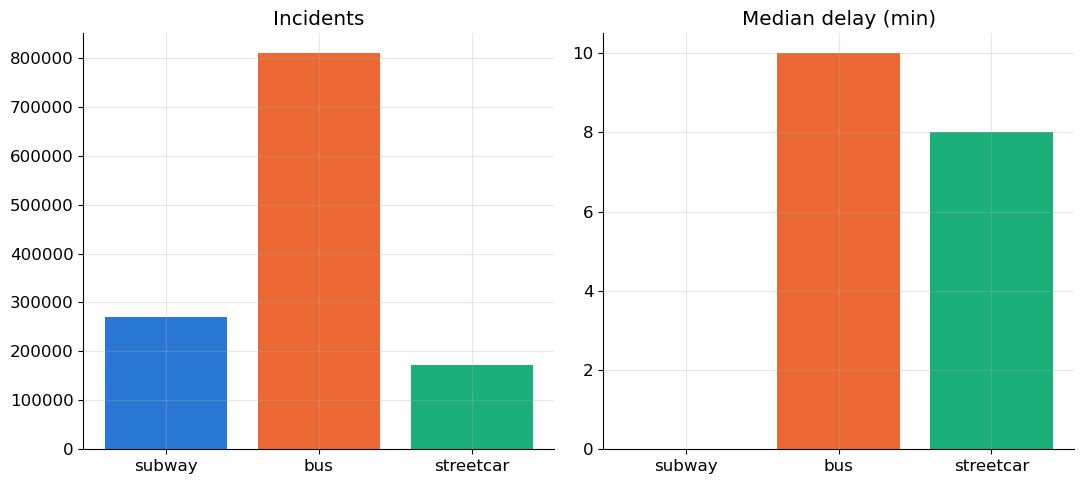

In [10]:
# Delays by mode
summary = df.groupby("mode").agg(incidents=("delay", "size"), median_delay=("delay", "median")).reindex(MODES)
summary["delay_hours"] = df.groupby("mode")["delay"].sum().reindex(MODES) / 60
display(summary.round(1))

fig, axes = plt.subplots(1, 2)
for ax, col, title in [(axes[0], "incidents", "Incidents"), (axes[1], "median_delay", "Median delay (min)")]:
    ax.bar(MODES, summary[col], color=[COLORS[m] for m in MODES])
    ax.set_title(title)
plt.tight_layout()

Text(0, 0.5, 'incidents')

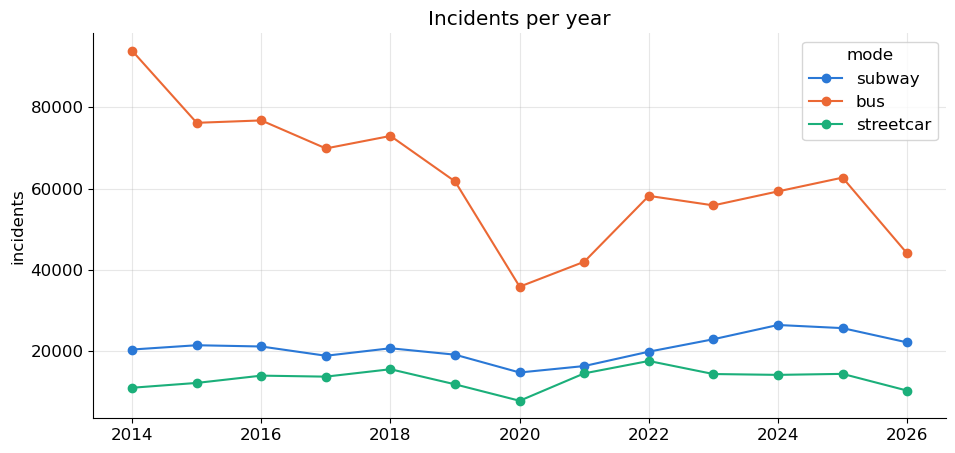

In [11]:
# Incidents per year
yearly = df.groupby(["year", "mode"]).size().unstack()[MODES]
ax = yearly.plot(marker="o", color=COLORS, title="Incidents per year")
ax.set_xlabel(""); ax.set_ylabel("incidents")

Text(0, 0.5, 'incidents')

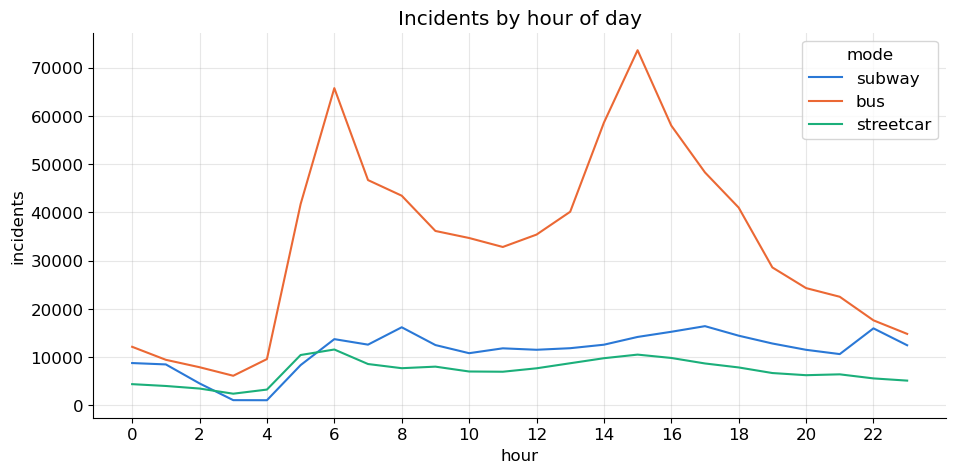

In [12]:
# Incidents by hour of day
hourly = df.groupby(["hour", "mode"]).size().unstack()[MODES]
ax = hourly.plot(color=COLORS, title="Incidents by hour of day")
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("hour"); ax.set_ylabel("incidents")

Text(0, 0.5, 'incidents')

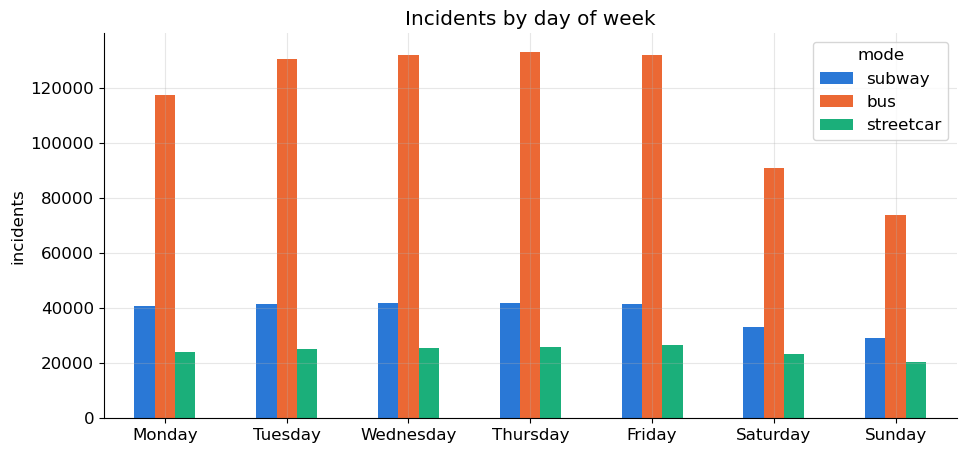

In [13]:
# Incidents by day of week
DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
daily = df.groupby(["day", "mode"]).size().unstack().reindex(DAYS)[MODES]
ax = daily.plot.bar(color=COLORS, title="Incidents by day of week", rot=0)
ax.set_xlabel(""); ax.set_ylabel("incidents")

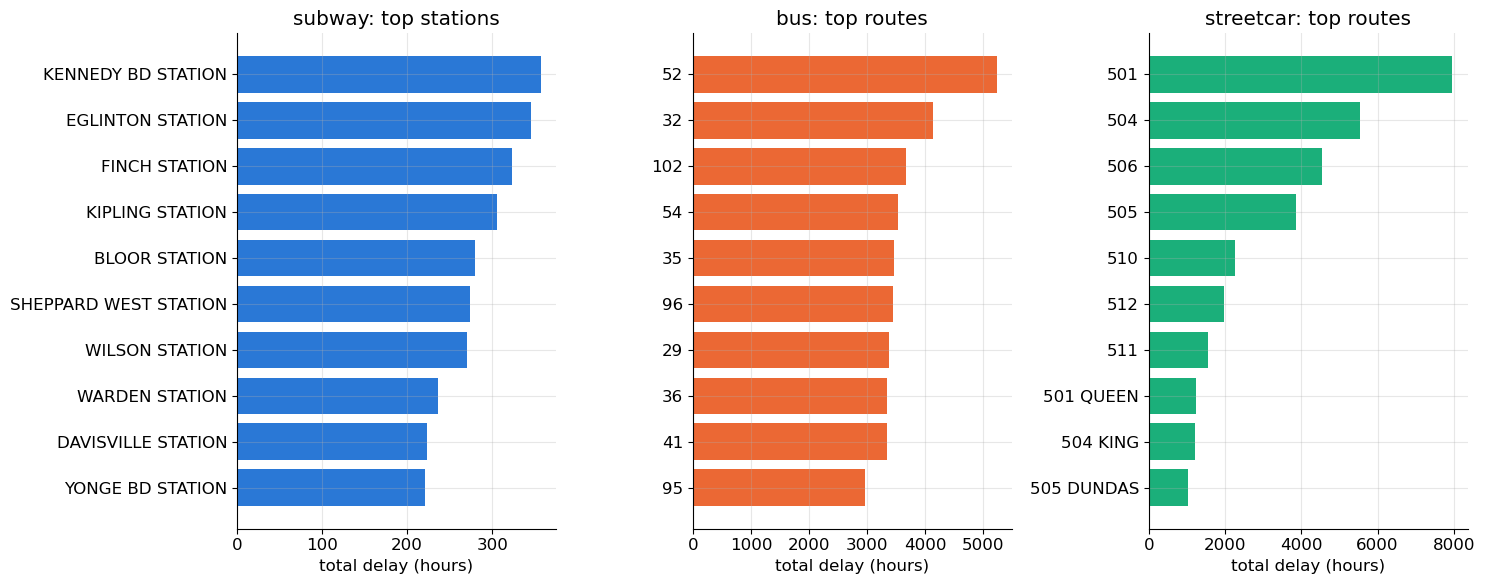

In [14]:
# Top 10 routes and stations
fig, axes = plt.subplots(1, 3, figsize=(15, 6))
for ax, mode in zip(axes, MODES):
    key = "location" if mode == "subway" else "route"
    top = df[df["mode"] == mode].groupby(key)["delay"].sum().div(60).nlargest(10).sort_values()
    ax.barh(top.index, top.values, color=COLORS[mode])
    ax.set_title(f"{mode}: top {'stations' if mode == 'subway' else 'routes'}")
    ax.set_xlabel("total delay (hours)")
plt.tight_layout()

Text(0.5, 0, 'delay (min)')

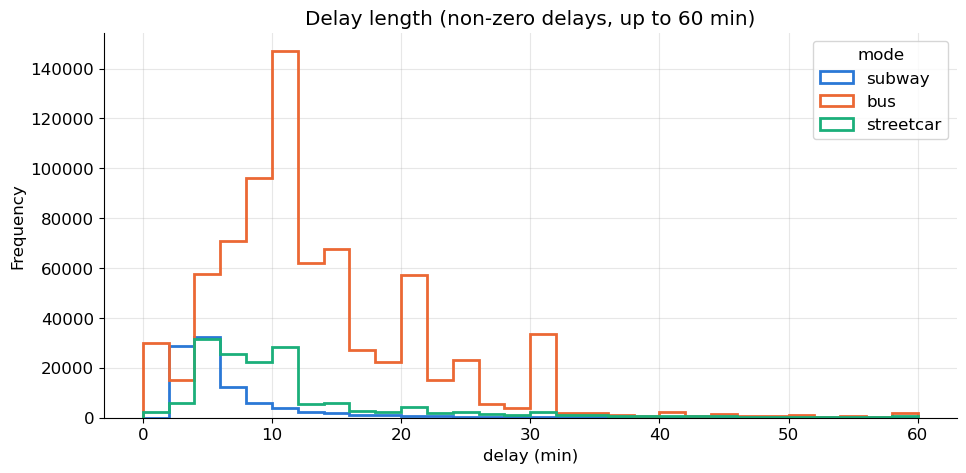

In [15]:
# Delay length
ax = df[df["delay"] > 0].pivot(columns="mode", values="delay")[MODES].plot.hist(
    bins=range(0, 61, 2), histtype="step", linewidth=2, color=COLORS, title="Delay length (non-zero delays, up to 60 min)")
ax.set_xlabel("delay (min)")